In [1]:
import torch

# from diffusers import DDPMPipeline
from diffusers import DiffusionPipeline
from matplotlib import pyplot as plt
from torchvision.utils import make_grid

In [2]:
# Set the device to use our GPU or CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
# Load the pipeline
image_pipe = DiffusionPipeline.from_pretrained("google/ddpm-celebahq-256", use_safetensors=False)
image_pipe.to(device)

Loading pipeline components...:   0%|          | 0/2 [00:00<?, ?it/s]

DDPMPipeline {
  "_class_name": "DDPMPipeline",
  "_diffusers_version": "0.41.0",
  "_name_or_path": "google/ddpm-celebahq-256",
  "scheduler": [
    "diffusers",
    "DDPMScheduler"
  ],
  "unet": [
    "diffusers",
    "UNet2DModel"
  ]
}

  0%|          | 0/1000 [00:00<?, ?it/s]

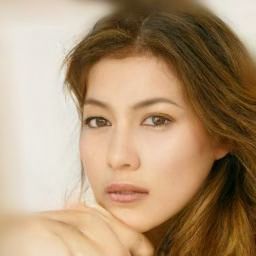

In [4]:
images = image_pipe().images
images[0]

In [5]:
def plot_noise_and_denoise(scheduler_output, step):
    _, axs = plt.subplots(1, 2, figsize=(12, 5))
    prev_prev_sample = scheduler_output.prev_sample
    grid = make_grid(prev_prev_sample, nrow=4).permute(1, 2, 0)
    axs[0].imshow(grid.cpu().clip(-1, 1) * 0.5 + 0.5)
    axs[0].set_title(f"Current x (step {step})")
    axs[0].axis("off")

    pred_x0 = scheduler_output.pred_original_sample
    grid = make_grid(pred_x0, nrow=4).permute(1, 2, 0)
    axs[1].imshow(grid.cpu().clip(-1, 1) * 0.5 + 0.5)
    axs[1].set_title(f"Predicted denoised images (step {step})")
    axs[1].axis("off")
    plt.show()

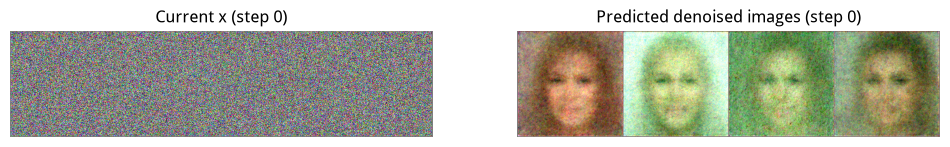

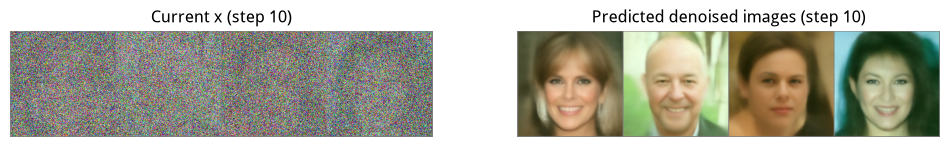

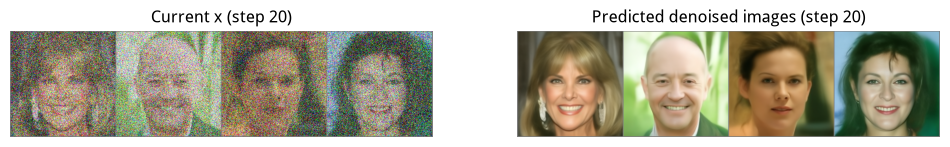

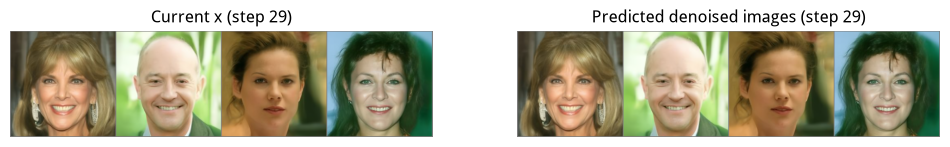

In [6]:
# 随机起始点是4张图像 每张图像都是3通道（RGB）、256x256像素的图像
image = torch.randn(4, 3, 256, 256).to(device)
# 设置特定的扩散步骤数量
image_pipe.scheduler.set_timesteps(num_inference_steps=30)
for i, t in enumerate(image_pipe.scheduler.timesteps):
    # 根据当前样本x和时间步t获取预测结果
    with torch.inference_mode():
        # 我们需要传入时间步t，以便模型知道它当前处于哪个时间步。
        noise_pred = image_pipe.unet(image, t)["sample"]
    # 计算使用调度器后更新后的x
    scheduler_output = image_pipe.scheduler.step(noise_pred, t, image)
    # 更新x
    image = scheduler_output.prev_sample
    # 同时展示x和预测的去噪图像
    if i % 10 == 0 or i == len(image_pipe.scheduler.timesteps) - 1:
        plot_noise_and_denoise(scheduler_output, i)